# AlertLens — how it works, from raw alerts to an explained incident

**AIC × CrowdStrike hackathon · Track 2: Detect (AI-powered Blue Team)**

This notebook walks through the whole solution in plain language, on the real data, with figures. Each section answers
one question and ends with a **"Say to the judges"** line you can repeat.

**The whole idea in five lines**

1. Security sensors produced **2.66 million alerts** in 8 company networks over ~5 days. Hidden inside: one real
   multi-step attack per network (≈ 0.45% of alerts).
2. We **merge duplicates** (2.66M → 99K "meta-alerts") and describe each one with ~100 numbers that answer questions like
   *"has this rule ever fired here before?"* and *"what else unusual is happening right now?"*.
3. A **machine-learning model (LightGBM)** learned from 7 networks which answers mean "attack", and is tested on the 8th,
   which it has never seen. Result: an analyst reviews **64 items instead of 12,017** to find 90% of the attack.
4. Every score comes with **reasons**: what is normal in this network, how this alert differs, and how much each
   difference pushed the score.
5. A **local LLM** (runs on the laptop, no data leaves) turns the top evidence into an incident report and answers the
   analyst's questions. The LLM explains; the ML model detects.

```
raw JSON alerts ─▶ 1 one table ─▶ 2 clean labels ─▶ 3 meta-alerts ─▶ 4 features ─▶ 5 ML model ─▶ score
                                                                                         │
             8 local-LLM report ◀─ 7 incidents (attack chains) ◀─ 6 reasons (SHAP + baseline) ◀┘
```

In [1]:
%pip install -q -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [2]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

from blueteam.baseline import LEARNING_HOURS, display_value, feature_info
from blueteam.explain import STAGE_MITRE, confidence_tier
from blueteam.llm import incident_context

DATA = Path("data")
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 90)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

alerts = pd.read_parquet(DATA / "alerts.parquet",
                         columns=["scenario", "source", "ts", "host", "rule_id", "rule_desc", "rule_level", "in_window"])
meta = pd.read_parquet(DATA / "meta_explained.parquet")
X = pd.read_parquet(DATA / "features.parquet")
labels = pd.read_csv("labels.csv")
incidents = json.load(open(DATA / "incidents.json"))
narratives = json.load(open(DATA / "narratives.json"))
stats = json.load(open(DATA / "stats.json"))
breakdown = pd.read_parquet(DATA / "score_breakdown.parquet").set_index("row")
baseline = pd.read_parquet(DATA / "feature_baseline.parquet").set_index(["scenario", "feature"])
lp = pd.DataFrame(json.load(open(DATA / "learning_periods.json"))).set_index("scenario")
dt = lambda s: pd.to_datetime(s, unit="s")
print(f"{len(alerts):,} raw alerts · {len(meta):,} meta-alerts · {int(meta.label.sum())} attack meta-alerts · "
      f"{X.shape[1]} features each")

2,655,821 raw alerts · 99,161 meta-alerts · 450 attack meta-alerts · 98 features each


## 1. The data: what the sensors give us

The [AIT Alert Data Set](https://zenodo.org/records/8263181) simulates **8 small companies** (fox, harrison,
russellmitchell, santos, shaw, wardbeck, wheeler, wilson). Each has normal employee/admin activity for days, and at some
point an attacker runs the same kind of multi-step attack. Three types of sensors watch each network:

| Sensor | What it watches | Example alert |
|---|---|---|
| **Wazuh** (host sensor, on each server) | system logs, logins, `sudo`, web-server logs | "Successful sudo to ROOT executed" |
| **Suricata** (network sensor) | network traffic vs. known attack signatures | "ET SCAN Possible Nmap User-Agent Observed" |
| **AMiner** (log-anomaly detector) | learns normal log patterns, complains about anything new | "New event type", "High entropy in Apache request" |

Each network has two files, `<network>_wazuh.json` (Wazuh + Suricata, forwarded through Wazuh) and
`<network>_aminer.json`, with **one alert per line**. A rule **"fires"** when its condition is met and it produces an
alert, like a smoke alarm going off.

In [3]:
raw = Path("ait_ads/santos_wazuh.json")
if raw.exists():
    with open(raw) as f:
        a = json.loads(f.readline())
    print("One raw Wazuh/Suricata alert (selected fields):")
    print(json.dumps({"timestamp": a.get("timestamp") or a.get("data", {}).get("timestamp"), "agent": a.get("agent"), "rule": a.get("rule"),
                      "src_ip": a.get("data", {}).get("src_ip"),
                      "signature": a.get("data", {}).get("alert", {}).get("signature")}, indent=1)[:1200])
    with open("ait_ads/santos_aminer.json") as f:
        b = json.loads(f.readline())
    print("\nOne raw AMiner alert (selected fields):")
    print(json.dumps({"detector": b["AnalysisComponent"]["AnalysisComponentType"],
                      "name": b["AnalysisComponent"]["AnalysisComponentName"],
                      "raw_log": b["LogData"]["RawLogData"][:1]}, indent=1)[:800])
else:
    print("raw dataset not present (download from Zenodo into ait_ads/) - the rest of the notebook still runs")

One raw Wazuh/Suricata alert (selected fields):
{
 "timestamp": "2022-01-14T00:00:09.728242+0000",
 "agent": {
  "ip": "192.168.104.218",
  "name": "wazuh-client",
  "id": "20"
 },
 "rule": {
  "firedtimes": 2,
  "mail": false,
  "level": 3,
  "description": "Suricata: Alert - ET INFO Observed DNS Query to .biz TLD",
  "groups": [
   "ids",
   "suricata"
  ],
  "id": "86601"
 },
 "src_ip": "192.168.104.218",
 "signature": "ET INFO Observed DNS Query to .biz TLD"
}

One raw AMiner alert (selected fields):
{
 "detector": "NewMatchPathDetector",
 "name": "AMiner: New event type.",
 "raw_log": [
  "type=USER_ACCT msg=audit(1642118401.749:517): pid=27892 uid=0 auid=4294967295 ses=4294967295 msg='op=PAM:accounting acct=\"www-data\" exe=\"/usr/sbin/cron\" hostname=? addr=? terminal=cron res=success'"
 ]
}


**Step 1 in our code (`blueteam/ingest.py`)** reads all 16 files and turns every alert, whatever the sensor, into one
row of one table: network, sensor, time, host, rule, severity, source IP, user, URL, raw log line.

In [4]:
counts = alerts.groupby(["scenario", "source"]).size().unstack(fill_value=0)
counts["total"] = counts.sum(axis=1)
counts.loc["ALL"] = counts.sum()
counts.style.format("{:,}")

source,aminer,suricata,wazuh,total
scenario,,,,
fox,"10,581","11,084","451,439","473,104"
harrison,"10,194","67,384","516,370","593,948"
russellmitchell,"4,056","9,186","32,302","45,544"
santos,"4,266","44,112","82,401","130,779"
shaw,"2,243","16,692","51,847","70,782"
wardbeck,"3,053","24,510","63,694","91,257"
wheeler,"12,222","68,629","535,310","616,161"
wilson,"8,943","65,038","560,265","634,246"
ALL,"55,558","306,635","2,293,628","2,655,821"


### Can you spot the attack? (the "alert fatigue" problem)

Below: every alert in the **santos** network, per hour. The orange bands are when the attacker was active (from
`labels.csv`). The attack does not stand out by volume — normal activity produces bigger bursts every day.

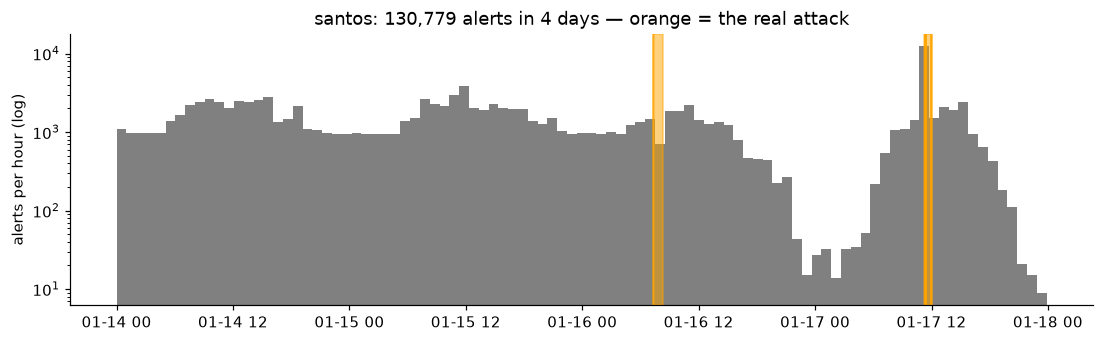

In [5]:
s = alerts[alerts.scenario == "santos"]
fig, ax = plt.subplots(figsize=(12, 3.2))
ax.hist(dt(s.ts), bins=int((s.ts.max() - s.ts.min()) // 3600), color="gray")
for r in labels[labels.scenario == "santos"].itertuples():
    ax.axvspan(dt(r.start), dt(max(r.end, r.start + 300)), color="orange", alpha=0.5)
ax.set_yscale("log"); ax.set_ylabel("alerts per hour (log)")
ax.set_title(f"santos: {len(s):,} alerts in 4 days — orange = the real attack")
plt.show()

### Why not just sort by severity?

That's what a SOC often does first. But in this data most attack alerts have the **same low severity levels** as
normal noise (levels 3 and 6), while normal activity also produces high-severity alerts — and the most dangerous steps
(switching user, running `sudo`) are "normal-looking" level 3–4 events. Ranking by severity scores a PR-AUC of only 0.006
(section 5).

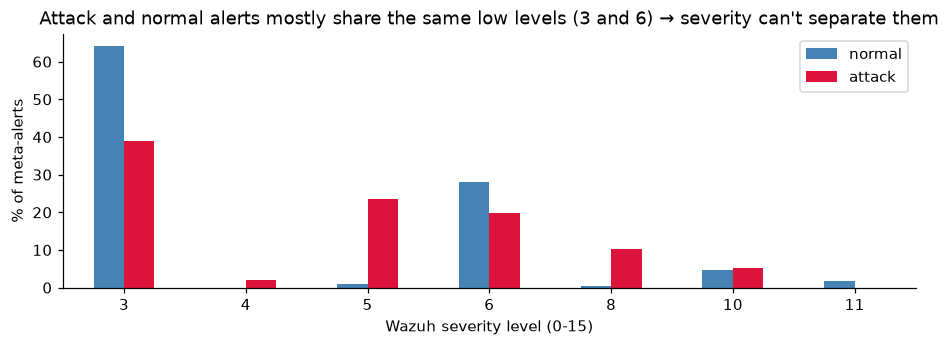

In [6]:
lvl = meta.groupby("label")["max_level"].value_counts(normalize=True).unstack(0).fillna(0).sort_index()
lvl.columns = ["normal", "attack"]
ax = (lvl * 100).plot.bar(figsize=(10, 3), color=["steelblue", "crimson"])
ax.set_xlabel("Wazuh severity level (0-15)"); ax.set_ylabel("% of meta-alerts")
ax.set_xticklabels([f"{v:.0f}" for v in lvl.index], rotation=0)
ax.set_title("Attack and normal alerts mostly share the same low levels (3 and 6) → severity can't separate them")
plt.show()

> *"2.66 million alerts, the attack is 0.45% of them, and severity doesn't help: sorting by
> Wazuh level, an analyst would review 12,017 items to find 90% of the attack."*

## 2. The answer key, and cleaning it

`labels.csv` tells us **when** each attack step happened in each network — not which alerts belong to it:

In [7]:
labels[labels.scenario == "santos"].assign(start=lambda d: dt(d.start), end=lambda d: dt(d.end))

,scenario,attack,start,end
30,santos,network_scans,2022-01-17 11:15:00,2022-01-17 11:21:30
31,santos,service_scans,2022-01-17 11:21:30,2022-01-17 11:22:00
32,santos,dirb,2022-01-17 11:22:00,2022-01-17 11:22:21
33,santos,wpscan,2022-01-17 11:22:21,2022-01-17 11:22:58
34,santos,webshell,2022-01-17 11:22:58,2022-01-17 11:24:16
35,santos,cracking,2022-01-17 11:24:16,2022-01-17 11:57:35
36,santos,reverse_shell,2022-01-17 11:57:35,2022-01-17 11:58:17
37,santos,privilege_escalation,2022-01-17 11:58:17,2022-01-17 11:58:59
38,santos,service_stop,2022-01-16 07:16:17,2022-01-16 07:16:19
39,santos,dnsteal,2022-01-16 07:16:19,2022-01-16 08:16:19


Problem: during those time windows, normal background activity keeps happening (mail logins, encrypted-traffic noise),
and it would wrongly count as "attack". So we **clean the labels** (`features.py → denoise_labels`): for every rule we
compare how often it fires *inside* attack windows vs. *outside*. Normal rules fire at about the same rate either way;
attack rules fire hundreds to millions of times more often during the attack. An alert counts as attack only if its rule
is **≥ 10× more frequent inside** the windows. (The labels are used only to train and to grade — never to score.)

In [8]:
lab = labels[labels.scenario == "santos"].sort_values("start")[["start", "end"]].to_numpy()
win, cur = 0.0, None
for st_, en in lab:
    if cur is None or st_ > cur[1]:
        win += 0 if cur is None else cur[1] - cur[0]; cur = [st_, en]
    else:
        cur[1] = max(cur[1], en)
win += cur[1] - cur[0]
out = (s.ts.max() - s.ts.min()) - win
g = s.groupby("rule_desc")["in_window"].agg(inside="sum", total="size")
g["outside"] = g.total - g.inside
g["times more frequent during attack"] = ((g.inside / win) / ((g.outside + 1) / out)).round(1)
print("Background rules (busiest overall) — NOT more frequent during the attack (ratio about 0-2):")
display(g.sort_values("total", ascending=False).head(5)[["inside", "outside", "times more frequent during attack"]])
print("Attack rules — vastly more frequent during the attack:")
display(g[g.inside >= 5].sort_values("times more frequent during attack", ascending=False)
        .head(5)[["inside", "outside", "times more frequent during attack"]])

Background rules (busiest overall) — NOT more frequent during the attack (ratio about 0-2):


,inside,outside,times more frequent during attack
rule_desc,,,
IDS event.,388,41619,0.5
Dovecot Authentication Success.,957,28590,1.8
Suricata: Alert - ET INFO Observed DNS Query to .biz TLD,0,25717,0.0
Suricata: Alert - SURICATA TLS invalid record/traffic,190,8736,1.2
Suricata: Alert - SURICATA TLS invalid handshake message,186,8736,1.2


Attack rules — vastly more frequent during the attack:


,inside,outside,times more frequent during attack
rule_desc,,,
Web server 400 error code.,7163,0,388919.9
Multiple web server 400 error codes from same source ip.,551,0,29916.9
AMiner: New request method in Apache Access log.,3266,8,19703.3
Suricata: Alert - ET SCAN Possible Nmap User-Agent Observed,15,0,814.4
Suspicious URL access.,12,0,651.5


## 3. Merging duplicates into "meta-alerts"

A single scan or password-cracking run makes the same rule fire thousands of times. We merge alerts with the same
**network + host + rule + source IP**, no more than 5 minutes apart, into one **meta-alert** (`features.py →
build_meta_alerts`). A meta-alert is labeled "attack" if at least half of its alerts are attack alerts.

Example from the santos attack — the attacker's directory-guessing tool (`dirb`) hitting the web server:

In [9]:
r = meta.loc[36596]
print(f"{r.n_alerts:,} raw alerts of '{r.rule_desc}' from {r.src_ip} on host {r.host}\n"
      f"between {dt(r.start):%H:%M:%S} and {dt(r.end):%H:%M:%S} → ONE meta-alert")
print(f"\nOverall: {stats['n_alerts']:,} raw alerts → {stats['n_meta']:,} meta-alerts "
      f"({1 - stats['n_meta'] / stats['n_alerts']:.1%} fewer items), of which {stats['n_attack_meta']} are attack")

7,155 raw alerts of 'Web server 400 error code.' from 172.21.128.119 on host 192.168.104.155
between 11:21:46 and 11:22:46 → ONE meta-alert

Overall: 2,655,821 raw alerts → 99,161 meta-alerts (96.3% fewer items), of which 450 are attack


## 4. Features: turning each meta-alert into answers to an analyst's questions

The model never sees raw IPs, hostnames or text. It sees **98 numbers per meta-alert**, each the answer to a question
an experienced analyst would ask. They are computed by small code blocks called **calcers** ("calculators" — the
config-driven design we reused from the Magnit hack), each answering one group of questions, **using only alerts that
happened before** (so it would work live, as alerts arrive):

| Calcer | Question it answers |
|---|---|
| `rule_rarity_causal` | Has this rule fired in this network before? In what share of past hours? |
| `context` | What else is happening network-wide in the same 10 minutes — how many rare rules, hosts, sensors? |
| `src_ip_causal` | Is this source IP new? How many hosts and rules has it touched? |
| `burst` | How big and fast is this burst (alerts, duration, distinct URLs/users/ports)? |
| `log_content` | Do the raw log lines show attacker behaviour (www-data switching user, `/etc/shadow`, shell without login, attack-tool user agent, PHP in uploads) or admin behaviour (SSH key login, commands from `/home`)? |
| `account` | Is this user account new on this host / in this network? |
| `semantics` | What kind of rule is it (authentication, web, MITRE tactic, log source)? |

Because the features describe **behaviour relative to this network** ("rare *here*", "new *here*") rather than
identities, a model trained on some networks works on a network it has never seen.

How different do attack and normal meta-alerts look on a few of these questions?

In [11]:
key = ["rule_hour_frac", "ctx_rare_rules", "ctx_hosts", "log_rule_meta_count", "ioc_attacker_score", "hours_since_ip_first"]
rows = []
for f in key:
    v = X[f]
    rows.append({"question": feature_info(f)[0],
                 "typical NORMAL meta-alert": display_value(f, v[meta.label == 0].median()),
                 "typical ATTACK meta-alert": display_value(f, v[meta.label == 1].median())})
pd.DataFrame(rows)

,question,typical NORMAL meta-alert,typical ATTACK meta-alert
0,Share of past hours this rule was active,72.3%,1.2%
1,"Rarely-seen detections network-wide, same 10 min",0,12
2,"Hosts alerting, same 10 min",6,15
3,Earlier bursts of this rule,"1,222",3
4,Attacker indicators in raw log lines,0,1
5,Hours since this source IP was first seen,6.1,83.4


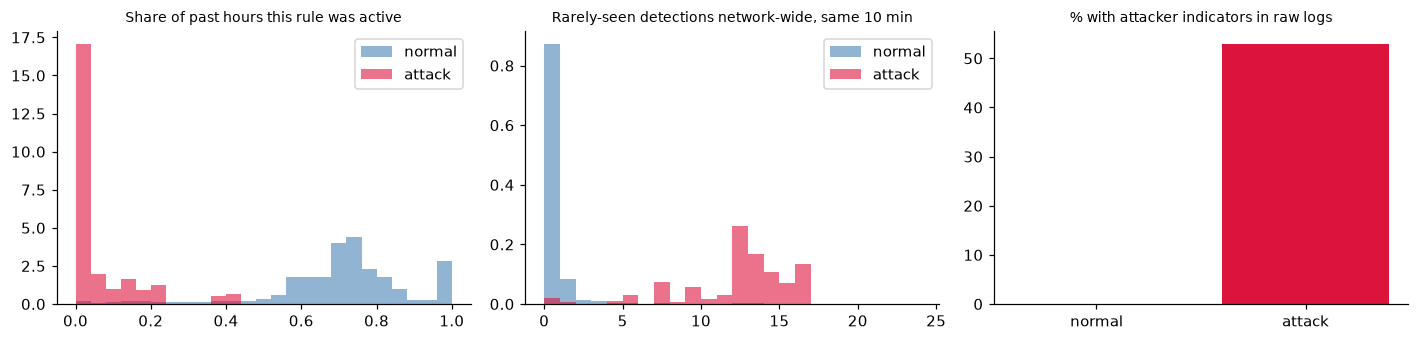

In [12]:
fig, axs = plt.subplots(1, 3, figsize=(13, 3.2))
for ax, f, bins in [(axs[0], "rule_hour_frac", np.linspace(0, 1, 26)), (axs[1], "ctx_rare_rules", np.arange(0, 25))]:
    for lab_, c, name in [(0, "steelblue", "normal"), (1, "crimson", "attack")]:
        ax.hist(X.loc[meta.label == lab_, f].dropna(), bins=bins, density=True, alpha=0.6, color=c, label=name)
    ax.set_title(feature_info(f)[0], fontsize=9); ax.legend()
share = X.assign(y=meta.label).groupby("y")["ioc_attacker_score"].apply(lambda v: (v > 0).mean() * 100)
axs[2].bar(["normal", "attack"], share.values, color=["steelblue", "crimson"])
axs[2].set_title("% with attacker indicators in raw logs", fontsize=9)
plt.tight_layout(); plt.show()

Reading the figure: normal alerts come from rules that are active most hours (left, blue on the right side) and happen
in quiet periods (middle, blue near 0). Attack alerts come from rules rarely or never seen here, during bursts of many
rare detections at once, and their raw logs often contain attacker tradecraft.

> *"We don't ask 'how severe is this rule?' — we ask 'is this unusual for this network right now,
> is something else unusual happening at the same time, and do the raw logs show attacker behaviour?'"*

## 5. Training: how the model learns what "attack" looks like

**Supervised learning** = show the computer many examples *with the answer* (attack / normal) and let it find the
rules that separate them. Our examples are the 99,161 meta-alerts with their 98 numbers and the cleaned label.

### The building block: a decision tree

A decision tree is a flowchart of yes/no questions learned from the data. Here is a tiny one (3 levels, 4 features),
trained on 7 networks and then tested on **santos**, which it never saw. How to read a box: the question at the top
(go left if *True*), `samples` = share of training examples reaching the box, `value` = [normal, attack] mix (attacks
weighted up because they are rare), `class` = the box's verdict (blue = attack, orange = normal).
The computer found these questions itself — e.g. *"more than 3.5 rare detections network-wide AND a rule active in under
44% of past hours → attack"*.

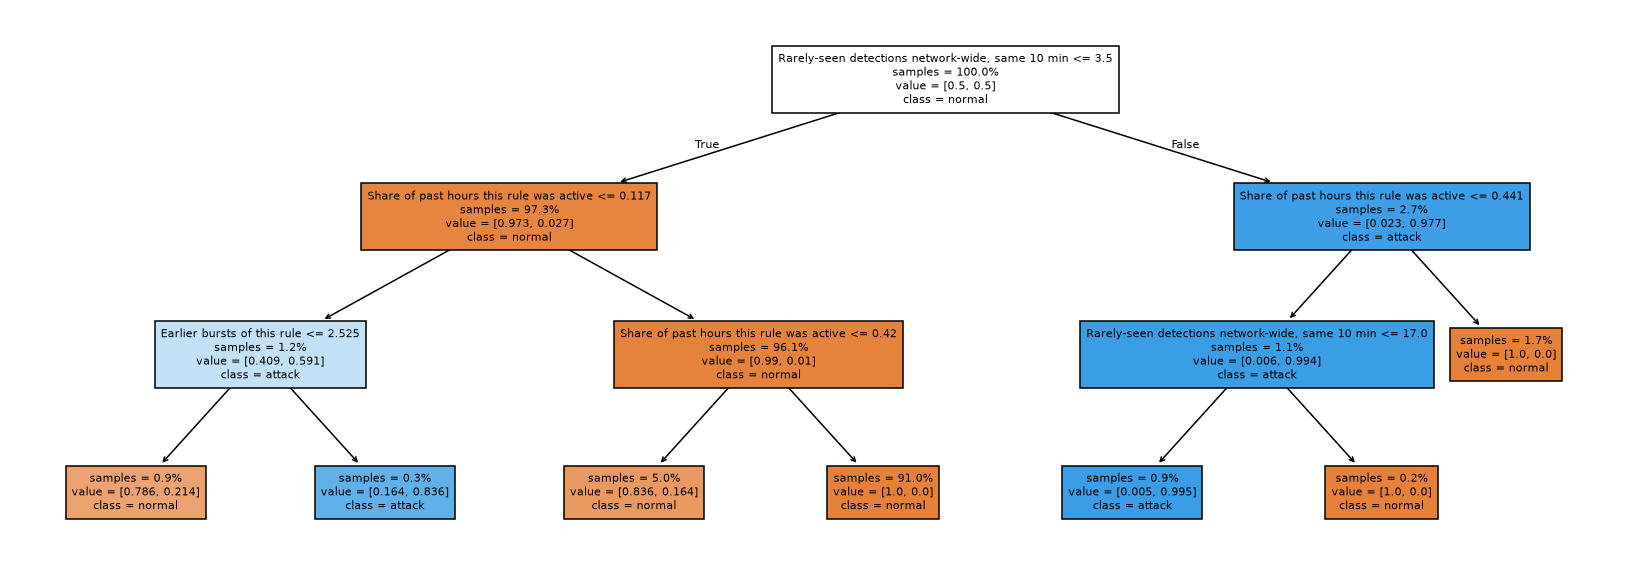

On santos (never seen): this 3-question tree scores PR-AUC 0.44; our full model scores 0.99


In [13]:
from sklearn.metrics import average_precision_score
from sklearn.tree import DecisionTreeClassifier, plot_tree

feats = ["rule_hour_frac", "ctx_rare_rules", "ioc_attacker_score", "log_rule_meta_count"]
Xf = X[feats].fillna(-1)
train = (meta.scenario != "santos").to_numpy()
tree = DecisionTreeClassifier(max_depth=3, class_weight="balanced", random_state=0).fit(Xf[train], meta.label[train])
fig, ax = plt.subplots(figsize=(19, 6.5))
plot_tree(tree, feature_names=[feature_info(f)[0] for f in feats], class_names=["normal", "attack"],
          filled=True, impurity=False, proportion=True, fontsize=7, ax=ax)
plt.show()
pr_tree = average_precision_score(meta.label[~train], tree.predict_proba(Xf[~train])[:, 1])
full = pd.read_csv(DATA / "metrics_by_scenario.csv").query("scenario == 'santos' and method == 'model'")["pr_auc"].item()
print(f"On santos (never seen): this 3-question tree scores PR-AUC {pr_tree:.2f}; our full model scores {full:.2f}")

### Our real model: LightGBM = hundreds of small trees working as a team

**LightGBM** (gradient boosting) builds **800 small trees one after another; each new tree focuses on the mistakes the
previous ones still make**, and the final score adds up all their votes. Details that matter:

- **Rare attacks get extra weight.** Only 450 of 99,161 examples are attacks, so each attack example counts 5× in
  training — otherwise the model could "win" by calling everything normal.
- **Each tree may only look at 30% of the features**, and strong regularisation keeps trees from memorising single
  examples. These settings came from a search over 16 configurations (`train.py --tune`).
- **5 copies with different random seeds are averaged** for stable scores.
- The output is a score from 0 to 1: the model's estimate that this meta-alert is part of an attack.

### The honest test: leave-one-network-out

If we tested on the same network we trained on, the model could just memorise "IP 172.21.128.119 is bad". So we train
on 7 networks and test on the 8th, 8 times — **every number we report is from a network the model never saw**, which
is exactly the situation of deploying it at a new customer.

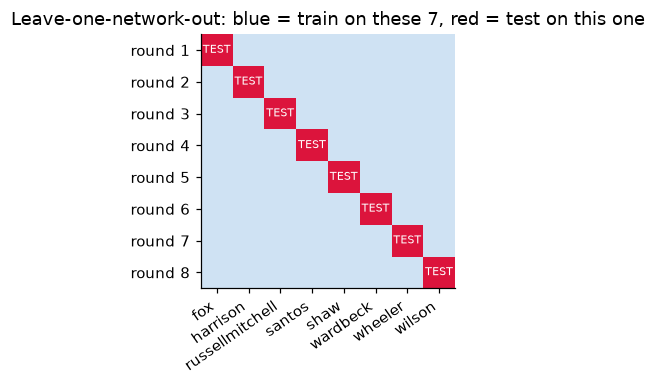

In [14]:
nets = sorted(meta.scenario.unique())
grid = np.array([[1 if i == j else 0 for j in range(8)] for i in range(8)])
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.imshow(grid, cmap=plt.matplotlib.colors.ListedColormap(["#cfe2f3", "crimson"]))
ax.set_xticks(range(8), nets, rotation=35, ha="right"); ax.set_yticks(range(8), [f"round {i + 1}" for i in range(8)])
for i in range(8):
    ax.text(i, i, "TEST", ha="center", va="center", color="white", fontsize=7)
ax.set_title("Leave-one-network-out: blue = train on these 7, red = test on this one")
plt.tight_layout(); plt.show()

### Results vs. what a SOC would do without us

**PR-AUC** in one sentence: *if the analyst works down our ranked list, how clean is the top?* 1.0 = every real attack
is above every false alarm; random ordering here would be ≈ 0.005.

In [15]:
summ = pd.read_csv(DATA / "metrics_summary.csv", index_col=0)
names = {"model": "AlertLens (ours)", "isoforest": "Isolation Forest (generic anomaly detector)",
         "rarity": "'Rarest rule first' heuristic", "wazuh_level": "Sort by Wazuh severity (status quo)"}
summ.rename(index=names)[["pr_auc", "p@20", "queue_size@90recall", "fp_suppressed@90recall"]].rename(columns={
    "pr_auc": "PR-AUC", "p@20": "share of real attacks in top 20", "queue_size@90recall": "items to review for 90% of attack",
    "fp_suppressed@90recall": "normal alerts hidden"}).style.format({
    "PR-AUC": "{:.3f}", "share of real attacks in top 20": "{:.0%}", "items to review for 90% of attack": "{:,.0f}",
    "normal alerts hidden": "{:.1%}"})

,PR-AUC,share of real attacks in top 20,items to review for 90% of attack,normal alerts hidden
method,,,,
AlertLens (ours),0.961,100%,64,99.9%
Isolation Forest (generic anomaly detector),0.366,51%,500,96.5%
'Rarest rule first' heuristic,0.143,24%,"1,295",89.5%
Sort by Wazuh severity (status quo),0.006,1%,"12,017",3.2%


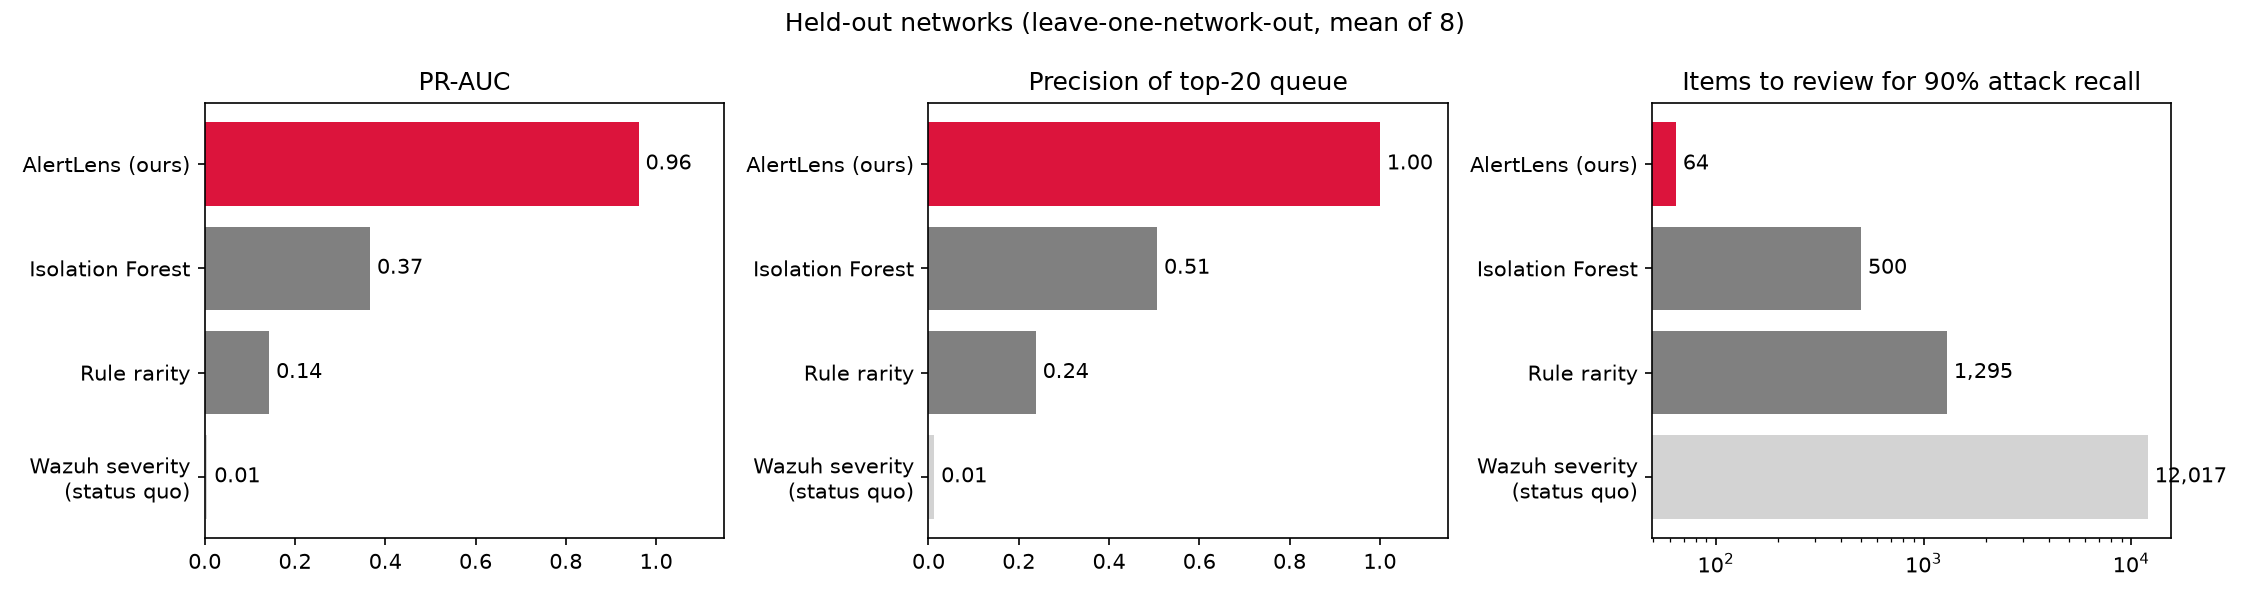

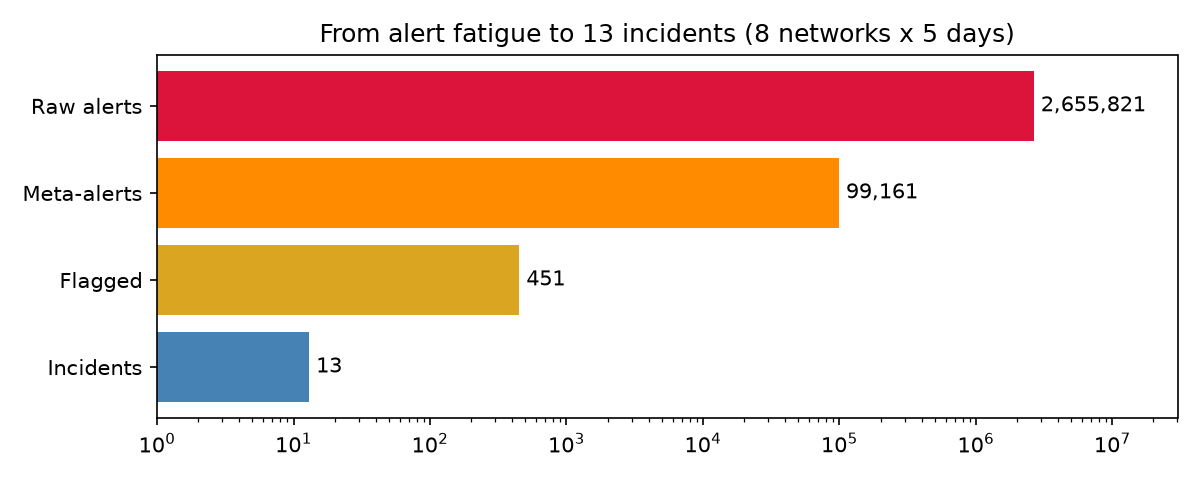

In [16]:
display(Image("figures/baselines.png"))
display(Image("figures/funnel.png"))

### Proof of what matters: ablation (remove an ingredient, retrain, compare)

In [17]:
abl = pd.read_csv(DATA / "ablation.csv")[["config", "n_features", "pr_auc", "queue_size@90recall"]]
abl.rename(columns={"pr_auc": "PR-AUC", "queue_size@90recall": "items to review"}).round(3)

,config,n_features,PR-AUC,items to review
0,all features,98,0.961,64.375
1,without context,91,0.943,101.875
2,without src_ip,92,0.957,63.000
3,without rule_rarity,91,0.937,61.375
4,without semantics,45,0.960,67.625
5,without log_content,88,0.959,62.625
6,without account,94,0.961,62.625
7,semantics only,53,0.495,4377.500


Knowing only *what* a rule is ("semantics only") gives PR-AUC 0.49. Knowing *how it behaves in this network* gives
0.96. Removing the time-window context costs only 0.02, so the model isn't just learning "when the attack happened".

> *"Trained on 7 networks, tested on an 8th it has never seen: PR-AUC 0.96, top-20 is 100%
> real attacks, and the review queue drops from 12,017 to 64."*

## 6. A real attack, step by step: how AlertLens catches it (santos, 17 January)

What the attacker did in santos (from `labels.csv`): scan the network → scan the website (`dirb`, `wpscan`) → upload a
**webshell** through WordPress → crack a user's password → open a **reverse shell** → **become root**.

We follow one of the most dangerous moments: at **11:58:17** the attacker, who is running as the web-server account
`www-data` through the webshell, **switches to the user `gmorgan`** with the cracked password, then runs `sudo` as root.

### Step A — the raw evidence the sensors produced

In [18]:
ATTACK = 37116   # 'User successfully changed UID' on intranet-server, santos
SUDO = 37118     # 'First time user executed sudo' right after it
for i in (ATTACK, SUDO):
    r = meta.loc[i]
    print(f"{dt(r.start):%m-%d %H:%M:%S}  {r.host:16}  Wazuh rule: '{r.rule_desc}' (severity {r.max_level:.0f})")
    print(f"    raw log: {r.sample_log}\n")

01-17 11:58:17  intranet-server   Wazuh rule: 'User successfully changed UID.' (severity 3)
    raw log: Jan 17 11:58:17 intranet-server su[20749]: + /dev/pts/1 www-data:gmorgan

01-17 11:58:27  intranet-server   Wazuh rule: 'First time user executed sudo.' (severity 4)
    raw log: Jan 17 11:58:27 intranet-server sudo:  gmorgan : TTY=pts/1 ; PWD=/var/www/intranet.smith.santos.com/wp-content/uploads/2022/01 ; USER=root ; COMMAND=list



Severity 3 — by severity alone, these would be buried among tens of thousands of similar items. To a human expert two
details scream "attack": `www-data:gmorgan` (the **web server** became a user — a website should never do that), and
`sudo` run from `/var/www/.../wp-content/uploads` (the **uploads folder of the website**, where the webshell lives).

### Step B — the features: this alert vs. what's normal in santos

The first **24 hours** of each network are the **learning period** that defines "normal" (no attack starts before hour
46 in any network). After it, every feature keeps using all earlier alerts — never later ones.

In [19]:
r, b = meta.loc[ATTACK], breakdown.loc[ATTACK]
L = lp.loc["santos"]
print(f"Learning period: first {LEARNING_HOURS} h ({dt(L.t0):%m-%d %H:%M} → {dt(L.learn_end):%m-%d %H:%M}), "
      f"{L.n_alerts_learning:,.0f} alerts. This alert comes {(r.start - L.t0) / 3600:.0f} h after monitoring started.\n")
rows = []
for f, v, c in json.loads(b.contrib):
    label, kind = feature_info(f)
    base = baseline.loc[("santos", f)]
    normal = (f"present in {base.nonzero:.1%} of alerts" if kind == "flag"
              else f"{display_value(f, base['median'])} (95% of alerts ≤ {display_value(f, base.p95)})")
    rows.append({"question": label, "THIS alert": display_value(f, v), "NORMAL in santos": normal,
                 "push on score": round(c, 2)})
pd.DataFrame(rows)

Learning period: first 24 h (01-14 00:00 → 01-15 00:00), 39,921 alerts. This alert comes 84 h after monitoring started.



,question,THIS alert,NORMAL in santos,push on score
0,Share of past hours this rule was active,0.0%,71.3% (95% of alerts ≤ 100.0%),3.46
1,"Rarely-seen detections network-wide, same 10 min",13,0 (95% of alerts ≤ 2),2.90
2,Attacker indicators in raw log lines,1,0 (95% of alerts ≤ 0),1.55
3,"Distinct rules firing network-wide, same 10 min",24,9 (95% of alerts ≤ 15),1.55
4,Earlier bursts of this rule,0,270 (95% of alerts ≤ 713),1.32
5,Occurrence number of this rule,1,271 (95% of alerts ≤ 714),0.91
6,Earlier alerts from this rule,0,"1,416 (95% of alerts ≤ 10,661)",0.59
7,"Source IP: 0 none, 1 internal, 2 external",0,2 (95% of alerts ≤ 2),0.38
8,Alert volume vs normal (x),1.4x,1.8x (95% of alerts ≤ 3.7x),0.24
9,Log source: auth,yes,present in 0.6% of alerts,0.18


### Step C — the score, and *why* (SHAP)

**SHAP** splits the model's score into the contribution of each feature — like an itemised receipt. It starts from the
score of a *typical* alert (almost 0%) and adds each push. The model works on a "log-odds" scale where **0 = 50/50 and
every +2.3 makes attack 10× more likely**. These numbers come from the models that did not see santos, and they add up
exactly to the score shown.

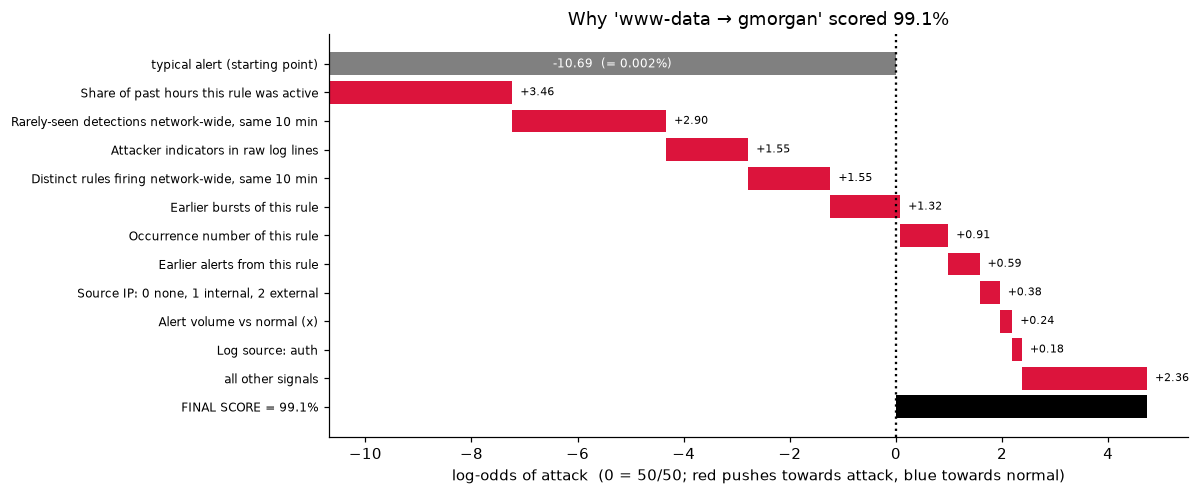

Plain-English reasons shown to the analyst:
  • rule never seen before in this network
  • 13 rarely-seen detections fired across the network in the same 10-min window
  • attacker indicators in raw logs: www-data user switch
  • 24 distinct rules firing in the same window


In [20]:
def waterfall(i, title):
    b = breakdown.loc[i]
    contrib = json.loads(b.contrib)
    names = ["typical alert (starting point)"] + [feature_info(f)[0] for f, _, _ in contrib] + ["all other signals"]
    vals = np.array([b.bias] + [c for *_, c in contrib] + [b.rest])
    starts = np.r_[0, np.cumsum(vals)[:-1]]
    colors = ["gray"] + ["crimson" if v > 0 else "steelblue" for v in vals[1:]]
    fig, ax = plt.subplots(figsize=(11, 4.6))
    ax.barh(range(len(vals)), vals, left=starts, color=colors)
    total = vals.sum()
    ax.barh(len(vals), total, color="black")
    ax.set_yticks(range(len(vals) + 1), names + [f"FINAL SCORE = {1 / (1 + np.exp(-total)):.1%}"], fontsize=8)
    ax.invert_yaxis(); ax.axvline(0, ls=":", color="k")
    for k, (s0, v) in enumerate(zip(starts, vals)):
        if k == 0:
            ax.text(s0 + v / 2, k, f"{v:+.2f}  (= {1 / (1 + np.exp(-v)):.3%})", va="center", ha="center",
                    color="white", fontsize=8)
        else:
            ax.text(s0 + v + (0.15 if v >= 0 else -0.15), k, f"{v:+.2f}", va="center",
                    ha="left" if v >= 0 else "right", fontsize=7)
    ax.set_xlabel("log-odds of attack  (0 = 50/50; red pushes towards attack, blue towards normal)")
    ax.set_title(title); plt.tight_layout(); plt.show()


waterfall(ATTACK, f"Why 'www-data → gmorgan' scored {meta.loc[ATTACK, 'score_model']:.1%}")
print("Plain-English reasons shown to the analyst:")
for x in json.loads(meta.loc[ATTACK, "reasons"]):
    print("  •", x["text"])

### Step D — which attack stage? (MITRE ATT&CK)

A second, smaller model (trained the same leave-one-network-out way, 90% accurate) predicts the kill-chain stage of
each flagged alert, and we map it to MITRE ATT&CK — the standard catalogue of attacker techniques.

In [21]:
st = meta.loc[ATTACK, "pred_stage"]
print(f"Predicted stage: {st}  →  MITRE: {STAGE_MITRE[st]}   (true phase from labels: {meta.loc[ATTACK, 'phase']})")

Predicted stage: Privilege escalation  →  MITRE: T1548.003 Sudo and Sudo Caching   (true phase from labels: privilege_escalation)


### Step E — from single alerts to one incident (the attack chain)

All flagged meta-alerts (score ≥ 0.5) in a network that are less than 60 minutes apart are chained into one
**incident**. Incidents are ranked by risk: more confident alerts, **more distinct attack stages** and more volume →
higher. The analyst opens one incident instead of thousands of alerts.

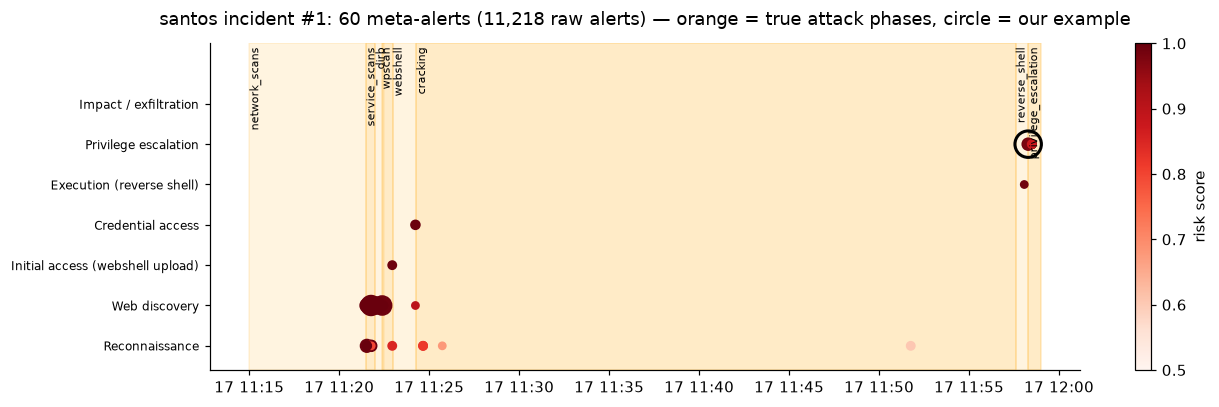

Incident risk 7.81, 6 stages, confidence tier: high; ranked #1 of 3 incidents in santos


In [23]:
inc = next(i for i in incidents if i["scenario"] == "santos" and i["rank_in_scenario"] == 1)
m = meta[(meta.scenario == "santos") & (meta.incident_id == inc["incident_id"])]
order = ["Reconnaissance", "Web discovery", "Initial access (webshell upload)", "Credential access",
         "Execution (reverse shell)", "Privilege escalation", "Impact / exfiltration"]
fig, ax = plt.subplots(figsize=(12, 3.8))
for r_ in labels[labels.scenario == "santos"].itertuples():
    if r_.end >= inc["start"] - 600:
        ax.axvspan(dt(r_.start), dt(max(r_.end, r_.start + 30)), color="orange", alpha=0.12 + 0.1 * (r_.Index % 2))
        ax.text(dt(r_.start), 7.4, r_.attack, rotation=90, fontsize=7, va="top")
y = m.pred_stage.map({s_: k for k, s_ in enumerate(order)})
sc_ = ax.scatter(dt(m.start), y, s=np.log1p(m.n_alerts) * 18 + 10, c=m.score_model, cmap="Reds", vmin=0.5, vmax=1)
ax.scatter(dt(meta.loc[ATTACK, "start"]), order.index(meta.loc[ATTACK, "pred_stage"]), s=300, facecolors="none",
           edgecolors="black", linewidths=2)
ax.set_yticks(range(len(order)), order, fontsize=8); ax.set_ylim(-0.6, 7.5)
ax.set_title(f"santos incident #1: {inc['n_meta']} meta-alerts ({inc['n_alerts']:,} raw alerts) — "
             f"orange = true attack phases, circle = our example", pad=12)
plt.colorbar(sc_, label="risk score"); plt.tight_layout(); plt.show()
print(f"Incident risk {inc['risk']:.2f}, {inc['n_stages']} stages, confidence tier: {confidence_tier(inc)}; "
      f"ranked #1 of {sum(i['scenario'] == 'santos' for i in incidents)} incidents in santos")

### Step F — the local LLM writes the report

The ML model has done the detection. Now the **LLM** (qwen3:14b running locally via Ollama) receives a compact text
summary of the incident — the top evidence per stage with times, hosts, IPs, rules, scores and reasons — and writes the
report a SOC analyst would write. This is what it receives (first lines):

In [24]:
ctx = incident_context(meta, inc)
print("\n".join(ctx.splitlines()[:9]), "\n...")

Incident #1 in network 'santos': 01-17 11:21:32 -> 01-17 11:58:54 UTC, 60 meta-alerts (11,218 raw alerts), sensors=['aminer', 'suricata', 'wazuh'], model-predicted stages=['Reconnaissance', 'Web discovery', 'Initial access (webshell upload)', 'Credential access', 'Execution (reverse shell)', 'Privilege escalation'], hosts=['10.229.0.4', '10.229.255.254', '172.21.128.119', '172.21.128.54', '172.21.131.50', '192.168.104.155', '192.168.104.214', '192.168.104.218', 'cloud-share', 'inet-dns', 'internal-share', 'intranet-server'], source IPs=['10.229.0.4', '10.229.2.216', '172.21.128.119', '172.21.131.50']
Model triage tier: high (max risk score 1.00, 6 kill-chain stage(s); 'high' = score >= 0.9 and >= 2 stages)
Evidence (time | host | sensor | rule | #alerts | src_ip | risk score | predicted stage | why flagged | sample log):
- 01-17 11:21:32 | 192.168.104.218 | aminer | AMiner: New event type. | 3 | - | 1.00 | Reconnaissance | rare rule here: active in only 14.4% of past hours; 14 rarely-s

In [25]:
display(Markdown(narratives[f"santos#{inc['incident_id']}"]))

### Verdict
TRUE POSITIVE (high confidence) - Multiple sensors detected a coordinated attack with clear signs of reconnaissance, web discovery, initial access via webshell, credential access, execution, and privilege escalation.

### What happened
- **01-17 11:21:32 UTC - Reconnaissance**: Multiple SSH connection attempts from `172.21.128.119` to various hosts (`cloud-share`, `mail`, `intranet-server`, `internal-share`) were flagged as insecure scans by Wazuh and AMiner.
- **01-17 11:21:46 UTC - Web discovery**: Nmap-like scanning detected via Suricata and Wazuh, with URLs such as `/nmaplowercheck1642418506` and `/sdk` being probed, indicating active enumeration of web services.
- **01-17 11:58:04 UTC - Execution (reverse shell)**: A high-entropy request was detected by AMiner, suggesting a webshell was uploaded and executed, with a suspicious PHP file (`yvmuplzucm-1642418578.1653.php`) being accessed.

### Affected assets & IOCs
- **Hosts**: `192.168.104.155`, `172.21.128.119`, `intranet-server`, `172.21.128.54`, `172.21.131.50`, `cloud-share`, `internal-share`, `mail`
- **Source IPs**: `172.21.128.119`, `172.21.131.50`
- **Accounts**: `www-data`, `gmorgan`
- **URLs**: `/nmaplowercheck1642418506`, `/sdk`, `/~test`, `/wp-content/uploads/2022/01/yvmuplzucm-1642418578.1653.php`, `/var/www/intranet.smith.santos.com/.h`

### MITRE ATT&CK
- **TA0043 Reconnaissance**: T1595 Active Scanning (via Nmap-like scanning)
- **T1595.003 Wordlist Scanning**: Probing of URLs and directories
- **T1190 Exploit Public-Facing App / T1505.003 Web Shell**: Webshell uploaded and accessed
- **T1110.002 Password Cracking**: High entropy in request suggests credential access
- **T1059 Command and Scripting Interpreter**: Execution of reverse shell
- **T1548.003 Sudo and Sudo Caching**: Privilege escalation via `sudo` and `su` commands

### Recommended response
1. **Isolate affected hosts**: Immediately isolate `192.168.104.155` and `172.21.128.119` from the network to prevent further lateral movement.
2. **Investigate and remove webshell**: Analyze the suspicious PHP file (`yvmuplzucm-1642418578.1653.php`) and remove it from the server.
3. **Audit user privileges**: Investigate the `gmorgan` account and the use of `sudo` and `su` commands, ensuring no unauthorized access or privilege escalation has occurred.
4. **Change compromised credentials**: Reset passwords for `www-data` and `gmorgan`, and enforce multi-factor authentication where possible.
5. **Review and update firewall rules**: Block traffic from `172.21.128.119` and `172.21.131.50`, and review all SSH and web server access logs for further anomalies.

## 7. The other side: rare but **normal** — how we avoid false alarms

The hard part of this track is *not* flagging normal activity. Here is the perfect contrast: the **same user
`gmorgan`, the same rule "First time user executed sudo"**, one day earlier — but this time it's the real admin reading
a log file from their home folder.

In [26]:
BENIGN = 37232
for i, tag in ((SUDO, "ATTACK"), (BENIGN, "NORMAL")):
    r = meta.loc[i]
    print(f"[{tag}] {dt(r.start):%m-%d %H:%M}  {r.host:16} score {r.score_model:.2f}\n    {r.sample_log}\n")

[ATTACK] 01-17 11:58  intranet-server  score 0.99
    Jan 17 11:58:27 intranet-server sudo:  gmorgan : TTY=pts/1 ; PWD=/var/www/intranet.smith.santos.com/wp-content/uploads/2022/01 ; USER=root ; COMMAND=list

[NORMAL] 01-16 08:27  mail             score 0.75
    Jan 16 08:27:38 mail sudo:  gmorgan : TTY=pts/0 ; PWD=/home/gmorgan ; USER=root ; COMMAND=/usr/bin/tail /var/log/syslog



Both are rare (a first-time `sudo` is rare by definition), so the model gives the normal one a fairly high score too
(0.75 — it *is* flagged). This is where the next layers help:

- The attack `sudo` is part of a **6-stage chain** with near-certain scores → incident tier **high**.
- The admin's `sudo` sits in a **single-stage** incident with no attacker indicators → tier **low**, ranked below the
  real attack, and the LLM — told to look for attacker behaviour and benign explanations — calls it **LIKELY BENIGN**:

In [27]:
binc = next(i for i in incidents if i["scenario"] == "santos" and i["incident_id"] == meta.loc[BENIGN, "incident_id"])
print(f"incident rank #{binc['rank_in_scenario']}, stages {binc['stages']}, tier: {confidence_tier(binc)}\n")
display(Markdown(narratives[f"santos#{binc['incident_id']}"].split("### What happened")[0]))

incident rank #2, stages ['Privilege escalation'], tier: low



### Verdict
**LIKELY BENIGN** (low confidence) - The evidence shows a single kill-chain stage (privilege escalation) with no explicit attacker behavior. The most plausible explanation is a legitimate user (gmorgan) performing a first-time sudo action, possibly during system maintenance or troubleshooting.

---



And a case the **model itself** clears: an SSH login on the russellmitchell mail server. The login rule *is* rare
there — a "rarest rule first" detector would flag it — but nothing else unusual is happening in the network, and the
raw log shows an administrator's SSH key login:

Jan 23 16:24:36 mail sshd[597]: Accepted publickey for jhall from 172.19.131.174 port 46580 ssh2: RSA SHA256:8wFbiaYPevKS/wYKnePO20v0iymTcrRh4Kr+1uRS1UM 



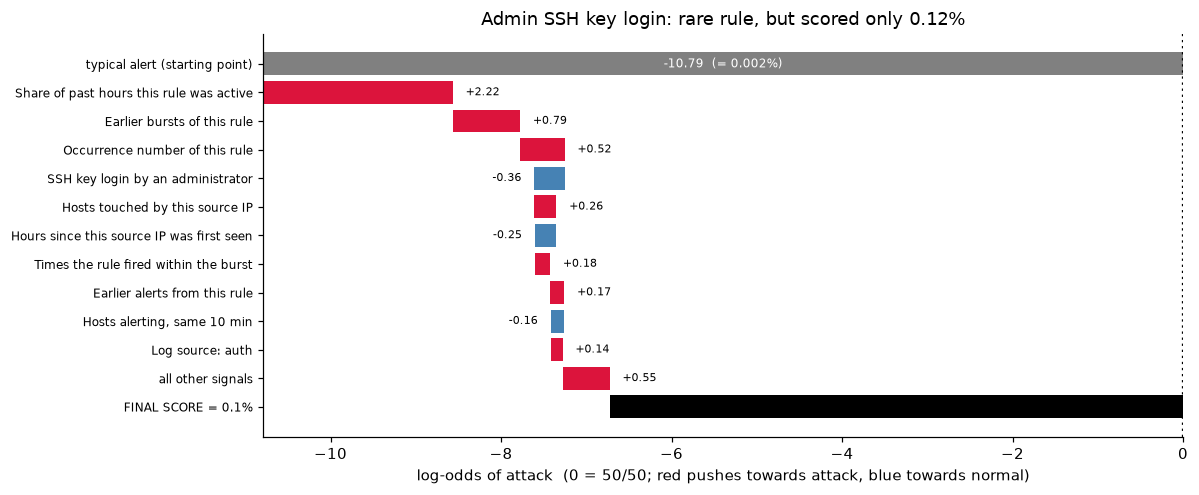

In [28]:
OK = 26181
print(meta.loc[OK, "sample_log"], "\n")
waterfall(OK, f"Admin SSH key login: rare rule, but scored only {meta.loc[OK, 'score_model']:.2%}")

In numbers: of the 451 flagged meta-alerts, 91% are real attack; most of the 41 "false" ones sit inside the attack
windows (attack traffic the time-based labels miss). Only **10 flagged items across all 8 networks** are truly outside
any attack — and the analyst can suppress a rule+host with one click in the dashboard ("Alert triage" tab).

## 8. The role of the LLM (and why it isn't the detector)

| | ML model (LightGBM) | LLM (qwen3:14b, local) |
|---|---|---|
| Job | **Detect & rank**: score every meta-alert | **Explain & assist**: write the report, answer questions |
| Input | 98 numbers per meta-alert | top ~25 pieces of evidence for one incident |
| Speed | all 99,161 meta-alerts in seconds | ~1–2 minutes per incident report |
| Strength | sees base rates across millions of alerts, measurable accuracy | turns evidence into language: timeline, IOCs, MITRE, next steps |

**Why not let the LLM read the alerts directly?** At even 1 second per alert, 2.66M alerts would take ~30 days; an LLM
can't see "this rule fires every hour in this network" from a single alert; and its accuracy is hard to measure and
can drift. So: **the ML model decides what's suspicious, the LLM explains it.**

How we keep the LLM honest:

- **Grounded**: it only receives our evidence, and is told to use only those facts (times, hosts, IPs, rules).
- **Not a rubber stamp**: it gets the incident's confidence tier and is told that rare ≠ malicious; it may only say
  TRUE POSITIVE for high-tier incidents or explicit attacker behaviour. Result: 9/9 real attack incidents → TRUE
  POSITIVE, 4/4 normal incidents → LIKELY BENIGN / NEEDS REVIEW.
- **Private**: it runs on the laptop via Ollama — no security telemetry leaves the company.
- **Interactive**: in the dashboard the analyst can ask "Which IP is the attacker? What do I block first?"

## 9. Results, limits, and what to say

**Results (all on networks the model never trained on)**

| | |
|---|---|
| Raw alerts → meta-alerts → flagged → incidents | 2,655,821 → 99,161 → 451 (91% real attack) → 13 |
| #1 incident is the real attack | **8 of 8 networks** |
| PR-AUC (1.0 = perfect ranking) | **0.96** (Isolation Forest 0.37, Wazuh severity 0.006) |
| Items to review to catch 90% of the attack | **64** (instead of 12,017) |
| Attack stage predicted correctly | 90% |

**Honest limits**

- Labels are time windows, so "attack" vs "normal" is approximate — we clean them, but some attack traffic is still
  labeled normal (that's most of our "false positives").
- **DNS exfiltration** (`dnsteal`) is mostly missed: the detector that would catch it fires all day on normal traffic.
  Next step: per-domain sequence features.
- The "high confidence" rule (score ≥ 0.9 and ≥ 2 stages) was chosen after seeing these results.
- 8 networks, one attack type: a real deployment needs more attack variety.

**Likely questions from judges — short answers**

- *How do you know it isn't overfitting?* — Every number is on a network the model never saw (leave-one-network-out);
  the tuning was checked with a nested version of the same test.
- *Isn't it just learning when the attack happened?* — Removing all time-window features costs only 0.02 PR-AUC; the
  features describe behaviour relative to the network, not clock time.
- *Would it work live?* — Yes: every feature uses only alerts that happened before the one being scored.
- *Why LightGBM and not deep learning / an LLM?* — Tabular data, 450 positive examples, needs to be fast and
  explainable: gradient-boosted trees are the standard winner there, and SHAP explains them exactly.
- *What does the analyst actually see?* — Ranked incidents with a kill-chain timeline, an AI report, a chat, and for
  every alert: baseline vs. now, the learning period, and the SHAP "receipt".

**Where things live in the code**

| Step | File |
|---|---|
| Read & normalise 16 JSON files | `blueteam/ingest.py` |
| Clean labels, meta-alerts, feature calcers | `blueteam/features.py` |
| Train, test leave-one-network-out, baselines, ablation, tuning | `blueteam/train.py` |
| Reasons, attack stage, incidents, confidence tier | `blueteam/explain.py` |
| Learning period, baselines, SHAP breakdown | `blueteam/baseline.py` |
| Local LLM report & chat | `blueteam/llm.py` |
| Dashboard | `app.py` |